# EMQA_L3_nic

**News impact curves of GJR-GARCH(1,1,1)-t models for the daily shocks of the Romanian base price, 2019-01-01 to 2026-10-31**

Energy Markets Quantitative Analysis (EMQA), Lecture 3 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L3/EMQA_L3_nic/EMQA_L3_nic.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}
C_PCT, C_EUR = PAL['RO'], PAL['c7']          # percent changes, EUR/MWh changes


def legend_bottom(fig, handles=None, labels=None, ncol=4, y=0.0):
    # legend centred under the axes, outside the plotting area
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
               handlelength=2.0, columnspacing=1.2)


def slide(label, key, x, k=None):
    # prints a number shown on the slide; [key] = its name in lectures/L3/L3_numbers.json
    if k is not None:
        x = round(float(x), k)
    print(f'{label:<58s} {x}   [{key}]')

## News impact curve (GJR)

$\sigma_t^2=\omega+(\alpha+\gamma I_{t-1})\varepsilon_{t-1}^2+\beta\sigma_{t-1}^2$, $I_{t-1}=1$ if $\varepsilon_{t-1}<0$. The curve sets $\sigma_{t-1}^2$ at its long-run level $\bar\sigma^2=\omega/(1-\alpha-\gamma/2-\beta)$ and plots $\sigma_t$ against the shock.

In [3]:
# Romanian daily base price (mean of all MTUs of the CET/CEST delivery day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month; panel from 2019-01-01, on the full calendar
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
P = PD['RO'].reindex(CAL)
print('Romania, daily base price:', START.date(), 'to', END.date(), '|', len(CAL), 'days, missing:', int(P.isna().sum()))

Romania, daily base price: 2019-01-01 to 2026-10-31 | 2861 days, missing: 0


In [4]:
# daily changes on the full calendar: percent (log) and EUR/MWh
r = 100 * np.log(P.where(P > 0)).diff()      # r_t = 100 ln(P_t / P_{t-1}); missing if a price is <= 0
u = P.diff()                                  # Delta P_t = P_t - P_{t-1}, EUR/MWh

In [5]:
import statsmodels.api as sm


def mean_design(y, lags=7):
    # constant + AR(1..7) + six day-of-week dummies (Monday = base)
    X = pd.DataFrame({f'L{k}': y.shift(k) for k in range(1, lags + 1)}, index=y.index)
    for j in range(1, 7):
        X[f'D{j}'] = (y.index.dayofweek == j).astype(float)
    X.insert(0, 'const', 1.0)
    return X


def mean_fit(y, lags=7):
    # OLS mean equation; returns (residuals = shocks, fitted model)
    X = mean_design(y, lags)
    df = pd.concat([y.rename('y'), X], axis=1).dropna()
    m = sm.OLS(df['y'], df.drop(columns='y')).fit()
    return m.resid, m


E_PCT, M_PCT = mean_fit(r)       # shocks epsilon_t, percent
E_EUR, M_EUR = mean_fit(u)       # shocks u_t, EUR/MWh
print('shocks:', E_PCT.index[0].date(), 'to', E_PCT.index[-1].date(), '|', len(E_PCT), 'days')

shocks: 2019-01-09 to 2026-10-31 | 2853 days


In [6]:
try:
    import arch
except ImportError:          # Google Colab: install the arch package once
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'arch'])
from arch import arch_model


def fit(e, vol='GARCH', o=0, dist='t'):
    # zero-mean GARCH(1,1) (o=0) or GJR-GARCH(1,1,1) (o=1), Student-t shocks by default
    return arch_model(np.asarray(e, float), mean='Zero', vol=vol, p=1, o=o, q=1, dist=dist,
                      rescale=False).fit(disp='off', show_warning=False)

### Numbers on the slide

In [7]:
NIC = {}
for un, e in [('pct', E_PCT), ('eur', E_EUR)]:
    p = fit(e, o=1).params
    s2 = p['omega'] / (1 - (p['alpha[1]'] + 0.5 * p['gamma[1]'] + p['beta[1]']))
    sd = np.sqrt(s2)
    x = np.linspace(-4 * sd, 4 * sd, 201)
    NIC[un] = (x, np.sqrt(p['omega'] + p['beta[1]'] * s2 + (p['alpha[1]'] + p['gamma[1]'] * (x < 0)) * x ** 2))
    slide(f'{un}: shock of 2 long-run std. dev.', f'garch.{un}.nic_2sd', 2 * sd, 1)
    slide(f'{un}: next-day sigma after a rise', f'garch.{un}.nic_up2', np.sqrt(p['omega'] + p['beta[1]'] * s2 + p['alpha[1]'] * (2 * sd) ** 2), 2)
    slide(f'{un}: next-day sigma after a fall', f'garch.{un}.nic_dn2',
          np.sqrt(p['omega'] + p['beta[1]'] * s2 + (p['alpha[1]'] + p['gamma[1]']) * (2 * sd) ** 2), 2)

pct: shock of 2 long-run std. dev.                         39.7   [garch.pct.nic_2sd]
pct: next-day sigma after a rise                           23.7   [garch.pct.nic_up2]
pct: next-day sigma after a fall                           30.27   [garch.pct.nic_dn2]
eur: shock of 2 long-run std. dev.                         61.4   [garch.eur.nic_2sd]
eur: next-day sigma after a rise                           37.63   [garch.eur.nic_up2]
eur: next-day sigma after a fall                           30.6   [garch.eur.nic_dn2]


### Chart

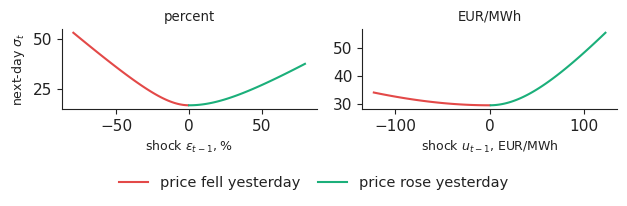

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(6.4, 2.1))
for ax, un, xl in [(axs[0], 'pct', r'shock $\varepsilon_{t-1}$, %'), (axs[1], 'eur', r'shock $u_{t-1}$, EUR/MWh')]:
    x_, s_ = NIC[un]
    ax.plot(x_[x_ < 0], s_[x_ < 0], color=PAL['c8'], lw=1.5)
    ax.plot(x_[x_ >= 0], s_[x_ >= 0], color=PAL['HU'], lw=1.5)
    ax.set_xlabel(xl, fontsize=9)
axs[0].set_ylabel(r'next-day $\sigma_t$', fontsize=9)
axs[0].set_title('percent', fontsize=9.5)
axs[1].set_title('EUR/MWh', fontsize=9.5)
legend_bottom(fig, handles=[plt.Line2D([], [], color=PAL['c8'], lw=1.5), plt.Line2D([], [], color=PAL['HU'], lw=1.5)],
              labels=['price fell yesterday', 'price rose yesterday'], ncol=2)
fig.tight_layout(rect=(0, 0.15, 1, 1))
plt.savefig('nic.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()